# ResNet50 congelada para prever pCR (BreastDCEDL I-SPY1 MinCrop) — notebook de execução

Este notebook **executa** o experimento completo usando somente as funções do arquivo `resnet50_pcr.py`. Ele não reimplementa nada do módulo.

**Antes de começar**
1. `Ambiente de execução → Alterar o tipo de ambiente de execução → GPU` (T4 é suficiente).
2. No Google Drive, crie a pasta `MyDrive/resnet50_pcr/` contendo:
   - o arquivo `resnet50_pcr.py`;
   - o CSV de metadados do I-SPY1 (172 pacientes, colunas `pid`, `pCR`, `test`, `pre`, `post_early`, `post_late`, ...);
   - (opcional) a pasta `resultados/` com `modelos/` e `figuras/` já gerados. Os modelos existentes são reaproveitados, sem retreino e sem nova avaliação do teste.
3. **Não é preciso subir o dataset.** Na primeira sessão, o notebook o baixa do Zenodo (~1,3 GB, alguns minutos) e guarda uma cópia em `MyDrive/resnet50_pcr/dados/`. Nas sessões seguintes, ele copia do Drive.
4. Abra este notebook **a partir do Drive** (clique duplo → Abrir com → Google Colaboratory) e edite **apenas a célula 1 (Configuração)**.

**Ordem e tempo aproximado (GPU T4)**

| Etapa | Célula | Tempo |
|---|---|---|
| Ambiente, Drive, dataset, módulo | 1–5 | 2–10 min (download do dataset, se necessário) |
| Metadados, partições e auditoria | 6–8 | ~2 min |
| Extração de características, imagem inteira | 9 | ~16 min |
| Extração de características, recorte tumoral (opcional) | 10 | ~15 min |
| Treino das cabeças (8 ou 16 modelos) | 11 | ~1 min |
| Avaliação no teste (uma única vez) | 12 | < 1 min |
| Grad-CAM | 13 | ~2 min |
| Modelo completo para a apresentação | 14 | < 1 min |
| Conferência dos arquivos | 15 | segundos |

As células são **retomáveis**: se a sessão cair, rode de novo da célula 1 em diante. Características, modelos e avaliações que já existem na pasta de resultados não são recalculados.

**Fora do `resnet50_pcr.py`** (código escrito diretamente nas células, não no módulo):
- os gráficos de convergência da loss;
- o intervalo de confiança da AUC por bootstrap;
- a figura do Grad-CAM e a medida de concentração no tumor;
- o registro dos tempos de extração;
- a conferência final.

In [ ]:
# =====================================================================
# 1. CONFIGURAÇÃO 
# =====================================================================
import os

# Google Drive: código, CSV e resultados ficam lá e sobrevivem entre sessões.
# Estrutura esperada no Drive (ver README do projeto):
#   MyDrive/resnet50_pcr/
#     resnet50_pcr.py
#     BreastDCEDL_SPY1_min_crop_metadata.csv
#     executar_resnet50_pcr.ipynb
#     dados/        <- o notebook guarda aqui uma cópia do dataset (.tar.gz) baixado do Zenodo
#     resultados/   <- modelos, figuras, tabelas; características e pesos são gerados aqui
# Se a montagem do Drive falhar, use False: tudo fica em /content e você baixa um ZIP no fim.
USAR_DRIVE = True
PASTA_DRIVE = "/content/drive/MyDrive/resnet50_pcr"

# O dataset é EXTRAÍDO no disco local do Colab.
# Ordem de busca: pasta local já extraída -> .tar.gz guardado no Drive -> download do Zenodo
# (e, com o Drive ativo, o .tar.gz baixado é guardado em dados/ para as próximas sessões).
PASTA_RAIZ_DATASET = "/content/BreastDCEDL/BreastDCEDL_ISPY1_min_crop"
BAIXAR_DATASET = True
URL_DATASET = "https://zenodo.org/records/18114231/files/BreastDCEDL_ISPY1_min_crop.tar.gz?download=1"
CAMINHO_TAR_DRIVE = os.path.join(PASTA_DRIVE, "dados", "BreastDCEDL_ISPY1_min_crop.tar.gz")

# CSV de metadados. I-SPY1 (172 linhas) 
CAMINHO_CSV = os.path.join(PASTA_DRIVE, "BreastDCEDL_SPY1_min_crop_metadata.csv") if USAR_DRIVE \
    else "/content/BreastDCEDL_SPY1_min_crop_metadata.csv"

# Onde está o resnet50_pcr.py (no Drive, ou enviado pelo painel de arquivos do Colab).
CAMINHO_MODULO = os.path.join(PASTA_DRIVE, "resnet50_pcr.py") if USAR_DRIVE else "/content/resnet50_pcr.py"

# Pasta de resultados (características, modelos, figuras, tabelas, pesos).
PASTA_RESULTADOS = os.path.join(PASTA_DRIVE, "resultados") if USAR_DRIVE else "/content/resultados"

# Experimento complementar com recorte da região tumoral (usa a máscara também na inferência).
RODAR_RECORTE = True

# Extrair as características (.npy) se não existirem? (~30 min na T4 para as duas famílias)
# Só são necessárias para TREINAR cabeças novas ou avaliar no teste um modelo ainda não avaliado.
# Com os 16 modelos já treinados e avaliados em resultados/modelos/, deixe False:
# o Grad-CAM e o modelo completo usam as imagens do dataset e os cabeca.pt, não os .npy.
GERAR_CARACTERISTICAS = False

# Hiperparâmetros FINAIS da cabeça, fixados antes do treino e iguais para todas as combinações.
TAXA_APRENDIZADO = 1e-4
DECAIMENTO_PESOS = 1e-2

# Modelo salvo por completo para a apresentação (cabeça E2 = treinada com todos os cortes).
MODELO_APRESENTACAO = "final_inteira_B_tres_fases_E2"

print("Resultados em:", PASTA_RESULTADOS)

Resultados em: /content/drive/MyDrive/resnet50_pcr/resultados


In [2]:
# =====================================================================
# 2. AMBIENTE: GPU e dependências
# =====================================================================
# O Colab já traz torch, torchvision, numpy, pandas, scipy, scikit-learn e matplotlib.
# nibabel (leitura de NIfTI) é instalado/garantido aqui.
!pip install -q nibabel

import subprocess, sys
import torch, torchvision, nibabel, numpy, pandas, scipy, sklearn, matplotlib
print("Python     ", sys.version.split()[0])
for modulo in (torch, torchvision, nibabel, numpy, pandas, scipy, sklearn, matplotlib):
    print(f"{modulo.__name__:11s}", modulo.__version__)
print("GPU disponível:", torch.cuda.is_available(),
      "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "sem GPU — a extração ficará MUITO lenta")

Python      3.13.16
torch       2.14.1+cu130
torchvision 0.29.1+cu130
nibabel     5.4.2
numpy       2.4.6
pandas      2.2.3
scipy       1.16.3
sklearn     1.6.1
matplotlib  3.10.0
GPU disponível: True | Tesla T4


In [ ]:
# =====================================================================
# 3. GOOGLE DRIVE
# =====================================================================
if USAR_DRIVE:
    from google.colab import drive
    try:
        drive.mount("/content/drive")
    except Exception as erro:
        raise RuntimeError(
            "A montagem do Drive falhou. Confira: (1) o Colab e o Drive estão na MESMA conta Google "
            "(canto superior direito); (2) na janela de autorização, marque TODAS as permissões; "
            "(3) cookies de terceiros liberados para colab.research.google.com; "
            "(4) Ambiente de execução -> Desconectar e excluir ambiente, e tente de novo. "
            "Sem Drive, use USAR_DRIVE = False na célula 1.") from erro
    os.makedirs(PASTA_DRIVE, exist_ok=True)
    for arquivo in (CAMINHO_MODULO, CAMINHO_CSV):
        print(("OK     " if os.path.exists(arquivo) else "FALTA  ") + arquivo)
else:
    print("Drive não utilizado: os resultados ficam em /content e se perdem ao fim da sessão.")
os.makedirs(PASTA_RESULTADOS, exist_ok=True)

Mounted at /content/drive
OK     /content/drive/MyDrive/resnet50_pcr/resnet50_pcr.py
OK     /content/drive/MyDrive/resnet50_pcr/BreastDCEDL_SPY1_min_crop_metadata.csv


In [4]:
# =====================================================================
# 4. DATASET: localizar (ou baixar) as pastas dce/ e mask/ e o CSV
# =====================================================================
import glob, shutil, tarfile, urllib.request
import pandas as pd

def localizar_raiz_dataset(pasta_busca):
    """Procura uma pasta que contenha as subpastas dce/ e mask/."""
    for atual, subpastas, _ in os.walk(pasta_busca):
        if "dce" in subpastas and "mask" in subpastas:
            return atual
    return None

import time

def baixar_com_progresso(url, destino, bloco=1 << 20):
    """Baixa para 'destino' mostrando MB, porcentagem e velocidade. Grava em .parte e só renomeia ao terminar,
    para uma interrupção não deixar um arquivo incompleto que pareça pronto."""
    temporario = destino + ".parte"
    inicio = ultimo = time.time()
    baixado = 0
    with urllib.request.urlopen(url) as resposta, open(temporario, "wb") as saida:
        total = int(resposta.headers.get("Content-Length") or 0)
        while True:
            parte = resposta.read(bloco)
            if not parte:
                break
            saida.write(parte)
            baixado += len(parte)
            agora = time.time()
            if agora - ultimo >= 5:
                velocidade = baixado / (agora - inicio) / 1e6
                percentual = f"{100 * baixado / total:5.1f}% de {total / 1e6:,.0f} MB" if total else f"{baixado / 1e6:,.0f} MB"
                print(f"  {percentual} | {velocidade:.1f} MB/s | {agora - inicio:.0f} s", flush=True)
                ultimo = agora
    os.replace(temporario, destino)
    print(f"  Download concluído: {baixado / 1e6:,.0f} MB em {time.time() - inicio:.0f} s")

if not (os.path.isdir(os.path.join(PASTA_RAIZ_DATASET, "dce")) and os.path.isdir(os.path.join(PASTA_RAIZ_DATASET, "mask"))):
    destino = os.path.dirname(PASTA_RAIZ_DATASET.rstrip("/"))
    os.makedirs(destino, exist_ok=True)
    arquivo_tar = os.path.join(destino, "BreastDCEDL_ISPY1_min_crop.tar.gz")
    if not os.path.exists(arquivo_tar):
        if USAR_DRIVE and os.path.exists(CAMINHO_TAR_DRIVE):
            print("Copiando o dataset guardado no Drive para o disco do Colab...")
            shutil.copy(CAMINHO_TAR_DRIVE, arquivo_tar)
        elif BAIXAR_DATASET:
            print("Baixando o dataset do Zenodo (~1,3 GB)...")
            baixar_com_progresso(URL_DATASET, arquivo_tar)
            if USAR_DRIVE:
                print("Guardando uma cópia no Drive para as próximas sessões...")
                os.makedirs(os.path.dirname(CAMINHO_TAR_DRIVE), exist_ok=True)
                shutil.copy(arquivo_tar, CAMINHO_TAR_DRIVE)
        else:
            raise FileNotFoundError(f"Não encontrei dce/ e mask/ em {PASTA_RAIZ_DATASET}, nem o .tar.gz no Drive. Ajuste a célula 1.")
    print("Extraindo (alguns minutos)...")
    with tarfile.open(arquivo_tar) as tar:
        membros = tar.getmembers()
        for numero, membro in enumerate(membros, start=1):
            tar.extract(membro, destino)
            if numero % 100 == 0 or numero == len(membros):
                print(f"  {numero}/{len(membros)} arquivos extraídos", flush=True)
    encontrada = localizar_raiz_dataset(destino)
    if encontrada is None:
        raise FileNotFoundError("O arquivo foi extraído, mas não encontrei uma pasta com dce/ e mask/. Verifique o conteúdo.")
    PASTA_RAIZ_DATASET = encontrada

print("Pasta do dataset:", PASTA_RAIZ_DATASET)
print("Arquivos em dce/:", len(os.listdir(os.path.join(PASTA_RAIZ_DATASET, "dce"))),
      "| em mask/:", len(os.listdir(os.path.join(PASTA_RAIZ_DATASET, "mask"))))

# CSV: se não estiver no caminho configurado, lista candidatos para você escolher
if not os.path.isfile(CAMINHO_CSV):
    candidatos = glob.glob("/content/**/*.csv", recursive=True)
    raise FileNotFoundError(f"CSV não encontrado em {CAMINHO_CSV}. Candidatos encontrados: {candidatos}")

# Se for o CSV combinado (coluna 'dataset' com várias coortes), grava uma cópia só com o I-SPY1.
# Não altera o arquivo original.
with open(CAMINHO_CSV, "r", newline="") as arquivo:
    texto = arquivo.read().replace("\r\n", "\n").replace("\r", "\n")
import io
tabela_csv = pd.read_csv(io.StringIO(texto))
if "dataset" in tabela_csv.columns and tabela_csv["dataset"].astype(str).str.lower().nunique() > 1:
    tabela_csv = tabela_csv[tabela_csv["dataset"].astype(str).str.strip().str.lower() == "spy1"]
    CAMINHO_CSV_ISPY1 = "/content/metadados_ispy1.csv"
    tabela_csv.to_csv(CAMINHO_CSV_ISPY1, index=False)
    print(f"CSV combinado detectado: {len(tabela_csv)} linhas do I-SPY1 copiadas para {CAMINHO_CSV_ISPY1}")
else:
    CAMINHO_CSV_ISPY1 = CAMINHO_CSV
print("CSV usado:", CAMINHO_CSV_ISPY1, "| linhas:", len(tabela_csv))

Baixando o dataset do Zenodo (~1,3 GB)...
    0.3% de 1,252 MB | 0.6 MB/s | 5 s
    0.6% de 1,252 MB | 0.6 MB/s | 12 s
    0.8% de 1,252 MB | 0.6 MB/s | 18 s
    1.1% de 1,252 MB | 0.6 MB/s | 23 s
    1.4% de 1,252 MB | 0.6 MB/s | 29 s
    1.8% de 1,252 MB | 0.6 MB/s | 35 s
    2.1% de 1,252 MB | 0.6 MB/s | 42 s
    2.4% de 1,252 MB | 0.6 MB/s | 48 s
    2.8% de 1,252 MB | 0.6 MB/s | 54 s
    3.1% de 1,252 MB | 0.6 MB/s | 60 s
    3.4% de 1,252 MB | 0.6 MB/s | 67 s
    3.8% de 1,252 MB | 0.6 MB/s | 73 s
    4.1% de 1,252 MB | 0.7 MB/s | 79 s
    4.4% de 1,252 MB | 0.7 MB/s | 85 s
    4.8% de 1,252 MB | 0.7 MB/s | 91 s
    5.1% de 1,252 MB | 0.7 MB/s | 97 s
    5.4% de 1,252 MB | 0.7 MB/s | 103 s
    5.8% de 1,252 MB | 0.7 MB/s | 109 s
    5.9% de 1,252 MB | 0.7 MB/s | 114 s
    6.2% de 1,252 MB | 0.6 MB/s | 120 s
    6.4% de 1,252 MB | 0.6 MB/s | 125 s
    6.7% de 1,252 MB | 0.6 MB/s | 131 s
    7.0% de 1,252 MB | 0.6 MB/s | 137 s
    7.4% de 1,252 MB | 0.6 MB/s | 143 s
    7.7% de 1,2

/tmp/ipykernel_502/397862336.py:60: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extract(membro, destino)


  100/691 arquivos extraídos
  200/691 arquivos extraídos
  300/691 arquivos extraídos
  400/691 arquivos extraídos
  500/691 arquivos extraídos
  600/691 arquivos extraídos
  691/691 arquivos extraídos
Pasta do dataset: /content/BreastDCEDL/BreastDCEDL_ISPY1_min_crop
Arquivos em dce/: 516 | em mask/: 172
CSV usado: /content/drive/MyDrive/resnet50_pcr/BreastDCEDL_SPY1_min_crop_metadata.csv | linhas: 172


In [5]:
# =====================================================================
# 5. MÓDULO resnet50_pcr.py
# =====================================================================
import shutil, importlib
if not os.path.isfile(CAMINHO_MODULO):
    raise FileNotFoundError(f"Envie o resnet50_pcr.py para {CAMINHO_MODULO} (painel de arquivos à esquerda) ou ajuste a célula 1.")
os.makedirs("/content/src", exist_ok=True)
if os.path.abspath(CAMINHO_MODULO) != "/content/src/resnet50_pcr.py":
    shutil.copy(CAMINHO_MODULO, "/content/src/resnet50_pcr.py")
if "/content/src" not in sys.path:
    sys.path.append("/content/src")
import resnet50_pcr as rp
importlib.reload(rp)

caminhos = rp.CaminhosDataset.a_partir_da_raiz(PASTA_RAIZ_DATASET, CAMINHO_CSV_ISPY1)
caminhos.validar()
rp.definir_semente()
dispositivo = rp.obter_dispositivo()
print("Módulo carregado. Dispositivo:", dispositivo)
print("Configurações de entrada:", list(rp.CONFIGURACOES_ENTRADA))
print("Estratégias:", rp.ESTRATEGIAS)
print("Normalização: P", rp.PERCENTIL_INFERIOR, "– P", rp.PERCENTIL_SUPERIOR, "(conjunta, por paciente)")

Módulo carregado. Dispositivo: cuda
Configurações de entrada: ['B_tres_fases', 'A_pre', 'A_post_early', 'A_post_late']
Estratégias: {1: 'maior_area', 2: 'todos_cortes_media'}
Normalização: P 1.0 – P 99.9 (conjunta, por paciente)


## Dados: metadados, partições e auditoria

As partições são as **oficiais** do CSV (coluna `test`: 0 = treino, 1 = teste, 2 = validação). A auditoria confere todos os 172 pacientes:
- arquivos de fase;
- formatos;
- divergências entre o CSV e os arquivos (ex.: ISPY1_1139);
- presença de tumor na máscara.

In [6]:
# =====================================================================
# 6. METADADOS E PARTIÇÕES
# =====================================================================
metadados = rp.ler_metadados(caminhos.caminho_csv)
indices = rp.listar_indices_aquisicao(caminhos.pasta_dce)
contagem = metadados.groupby("particao")["pCR"].agg(pacientes="size", pCR="sum")
contagem["nao_pCR"] = contagem["pacientes"] - contagem["pCR"]
display(contagem)
assert len(metadados) == 172, f"Esperados 172 pacientes do I-SPY1, encontrados {len(metadados)}"

,pacientes,pCR,nao_pCR
particao,,,
teste,35,12,23
treino,104,26,78
validacao,33,11,22


In [7]:
# =====================================================================
# 7. AUDITORIA DO DATASET (lê cabeçalhos e máscaras; ~1–2 min)
# =====================================================================
auditoria = rp.auditar_dataset(caminhos, metadados)
auditoria.to_csv(os.path.join(PASTA_RESULTADOS, "auditoria_dataset.csv"), index=False)

/content/src/resnet50_pcr.py:177: AvisoDivergenciaDados: ISPY1_1139: índices do CSV [0, 2, 2] diferem dos arquivos [0, 1, 2]; usando a ordenação dos arquivos.
  warnings.warn(


Pacientes: 172 | cortes no total: 5152

Cortes por partição:
           pacientes  cortes  z_min  z_max
particao                                  
teste             35    1120     13     53
treino           104    2985     10     72
validacao         33    1047     12     52

Divergências CSV x arquivos: ['ISPY1_1139']
Pacientes sem tumor na máscara: []
Tumor tocando o 1º ou o último corte: ['ISPY1_1025', 'ISPY1_1035', 'ISPY1_1064', 'ISPY1_1101', 'ISPY1_1104', 'ISPY1_1120', 'ISPY1_1160', 'ISPY1_1205', 'ISPY1_1228']

Margem em z (profundidade real − faixa do tumor no CSV original):
margem_z
-28      1
-17      1
-16      1
-9       1
-1       1
 2       4
 3       4
 4     159
Name: count, dtype: int64


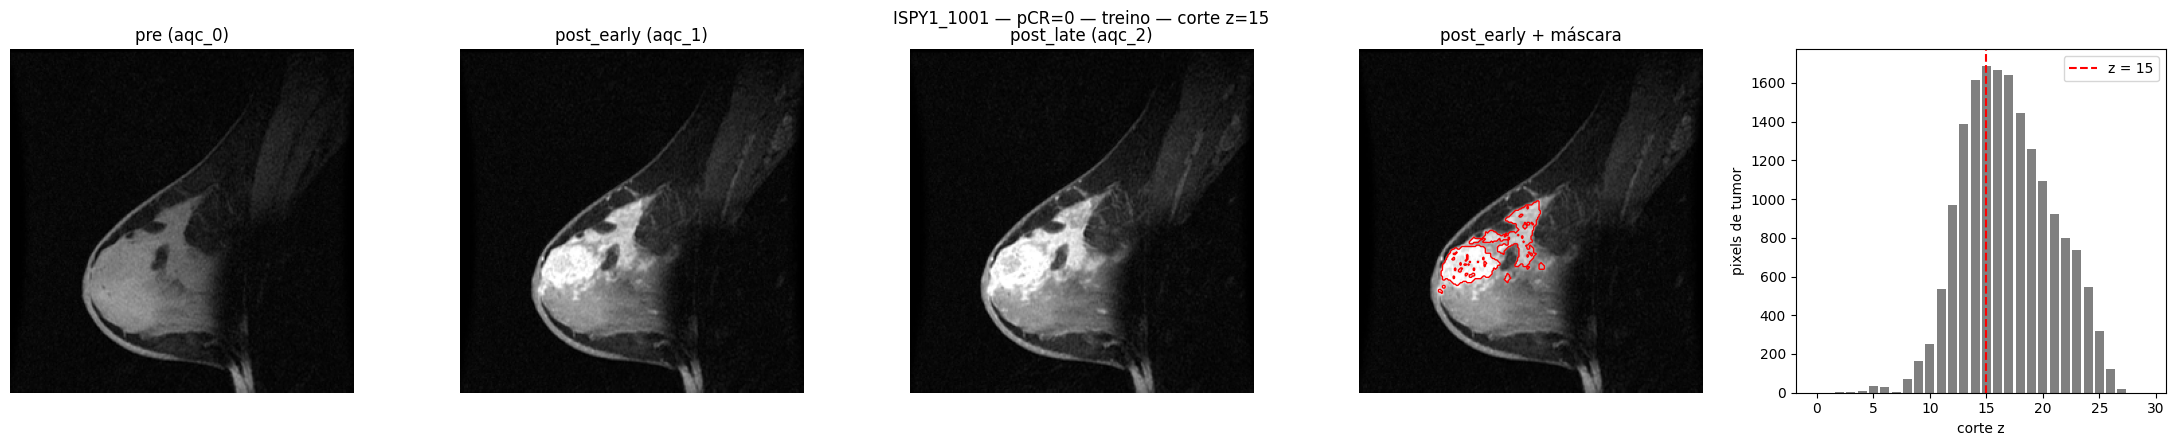

,min,p1,mediana,p99,max,media,media_tumor
pre,0.0,0.0,0.039,0.525,0.762,0.073,0.428
post_early,0.0,0.0,0.039,0.735,1.000,0.091,0.831
post_late,0.0,0.0,0.039,0.834,1.000,0.098,0.875


Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 118MB/s]


Parâmetros treináveis: 2,049 de 23,510,081


In [8]:
# =====================================================================
# 8. VERIFICAÇÃO VISUAL E DO MODELO
# =====================================================================
# Um paciente de treino: 3 fases normalizadas, máscara e área tumoral por corte
linha = metadados[metadados["particao"] == "treino"].iloc[0]
paciente = rp.carregar_paciente_normalizado(caminhos, linha, indices[linha["pid"]])
rp.visualizar_paciente(paciente)
display(rp.estatisticas_intensidade(paciente["normalizados"], paciente["mascara"]).round(3))

# ResNet50: só a nova cabeça é treinável
modelo = rp.criar_resnet50()
treinaveis, total = rp.contar_parametros(modelo)
print(f"Parâmetros treináveis: {treinaveis:,} de {total:,}")

## Extração antecipada de características

Com o backbone **congelado**, cada imagem gera sempre o mesmo vetor de 2048 características. Por isso cada imagem passa pela ResNet50 uma única vez, e os vetores são salvos em `.npy`.
- **Aumento de dados** (10 variações): só na partição de treino. A decisão é tomada dentro de `extrair_caracteristicas_particao`.
- **As 4 configurações de entrada** (B_tres_fases, A_pre, A_post_early, A_post_late) são extraídas na mesma passagem.
- **O teste também é extraído**, mas `carregar_caracteristicas` só o libera com `liberar_teste=True`, na avaliação final.

In [9]:
# =====================================================================
# 9. EXTRAÇÃO — imagem inteira (~16 min na T4; pula o que já existe)
# =====================================================================
import json, time

FAMILIAS = {"inteira": PASTA_RESULTADOS}
if RODAR_RECORTE:
    FAMILIAS["recorte"] = os.path.join(PASTA_RESULTADOS, "recorte")

def caracteristicas_completas(pasta):
    destino = os.path.join(pasta, "caracteristicas")
    esperados = [f"{nome}_{p}.npy" for nome in rp.CONFIGURACOES_ENTRADA for p in rp.PARTICOES]
    esperados += [f"registros_{p}.csv" for p in rp.PARTICOES]
    return all(os.path.exists(os.path.join(destino, arquivo)) for arquivo in esperados)

def extrair_familia(familia, pasta, recorte_tumoral):
    caminho_tempos = os.path.join(pasta, f"tempos_extracao_{familia}.json")
    if caracteristicas_completas(pasta):
        print(f"[{familia}] características já existem em {pasta} — extração pulada.")
        return
    if not GERAR_CARACTERISTICAS:
        print(f"[{familia}] GERAR_CARACTERISTICAS = False — extração pulada. "
              "Os modelos já salvos são usados; mude para True apenas se precisar treinar ou avaliar algo novo.")
        return
    rp.definir_semente()
    modelo = rp.criar_resnet50()
    tempos = {}
    for particao in rp.PARTICOES:
        caracteristicas, registros, duracao = rp.extrair_caracteristicas_particao(
            modelo, caminhos, metadados, indices, particao, recorte_tumoral=recorte_tumoral, dispositivo=dispositivo)
        rp.salvar_caracteristicas(caracteristicas, registros, particao, pasta=pasta)
        tempos[particao] = round(duracao, 1)
        print(f"[{familia}] {particao}: {len(registros)} imagens de {registros['pid'].nunique()} pacientes em {duracao:.0f} s")
    with open(caminho_tempos, "w") as arquivo:
        json.dump({"segundos_por_particao": tempos, "configuracoes": list(rp.CONFIGURACOES_ENTRADA),
                   "percentil_superior": rp.PERCENTIL_SUPERIOR, "pesos": "IMAGENET1K_V2",
                   "recorte_tumoral": recorte_tumoral}, arquivo, indent=2)

extrair_familia("inteira", FAMILIAS["inteira"], recorte_tumoral=False)

[inteira] GERAR_CARACTERISTICAS = False — extração pulada. Os modelos já salvos são usados; mude para True apenas se precisar treinar ou avaliar algo novo.


In [10]:
# =====================================================================
# 10. EXTRAÇÃO — recorte da região tumoral (opcional; experimento complementar)
# =====================================================================
# Quadrado ao redor do tumor (projeção da máscara 3D, margem de 25 %), ampliado para 224 x 224.
# Usa só os cortes com tumor. A ResNet continua congelada.
if RODAR_RECORTE:
    extrair_familia("recorte", FAMILIAS["recorte"], recorte_tumoral=True)
else:
    print("RODAR_RECORTE = False — família recorte não será usada.")

[recorte] GERAR_CARACTERISTICAS = False — extração pulada. Os modelos já salvos são usados; mude para True apenas se precisar treinar ou avaliar algo novo.


## Treino das cabeças

- **8 combinações:** 4 configurações × 2 estratégias.
  - **E1:** corte de maior área tumoral (e suas variações no treino).
  - **E2:** todos os cortes, com a média das probabilidades por paciente.
- **Hiperparâmetros:** fixados antes do treino e iguais para todas as combinações.
- **Early stopping** pela loss de validação. O teste **não** é usado aqui.
- **O que é salvo**, em `modelos/final_<família>_<configuração>_E<estratégia>/`:
  - `cabeca.pt` (pesos da melhor época);
  - `historico.csv`;
  - `metricas.json`;
  - `previsoes_treino.csv` e `previsoes_validacao.csv`.

Hiperparâmetros: HiperparametrosCabeca(taxa_aprendizado=0.0001, decaimento_pesos=0.01, tamanho_lote=256, max_epocas=200, paciencia=20)
final_inteira_B_tres_fases_E1: já treinado — carregando resultados salvos.
final_inteira_B_tres_fases_E2: já treinado — carregando resultados salvos.
final_inteira_A_pre_E1: já treinado — carregando resultados salvos.
final_inteira_A_pre_E2: já treinado — carregando resultados salvos.
final_inteira_A_post_early_E1: já treinado — carregando resultados salvos.
final_inteira_A_post_early_E2: já treinado — carregando resultados salvos.
final_inteira_A_post_late_E1: já treinado — carregando resultados salvos.
final_inteira_A_post_late_E2: já treinado — carregando resultados salvos.


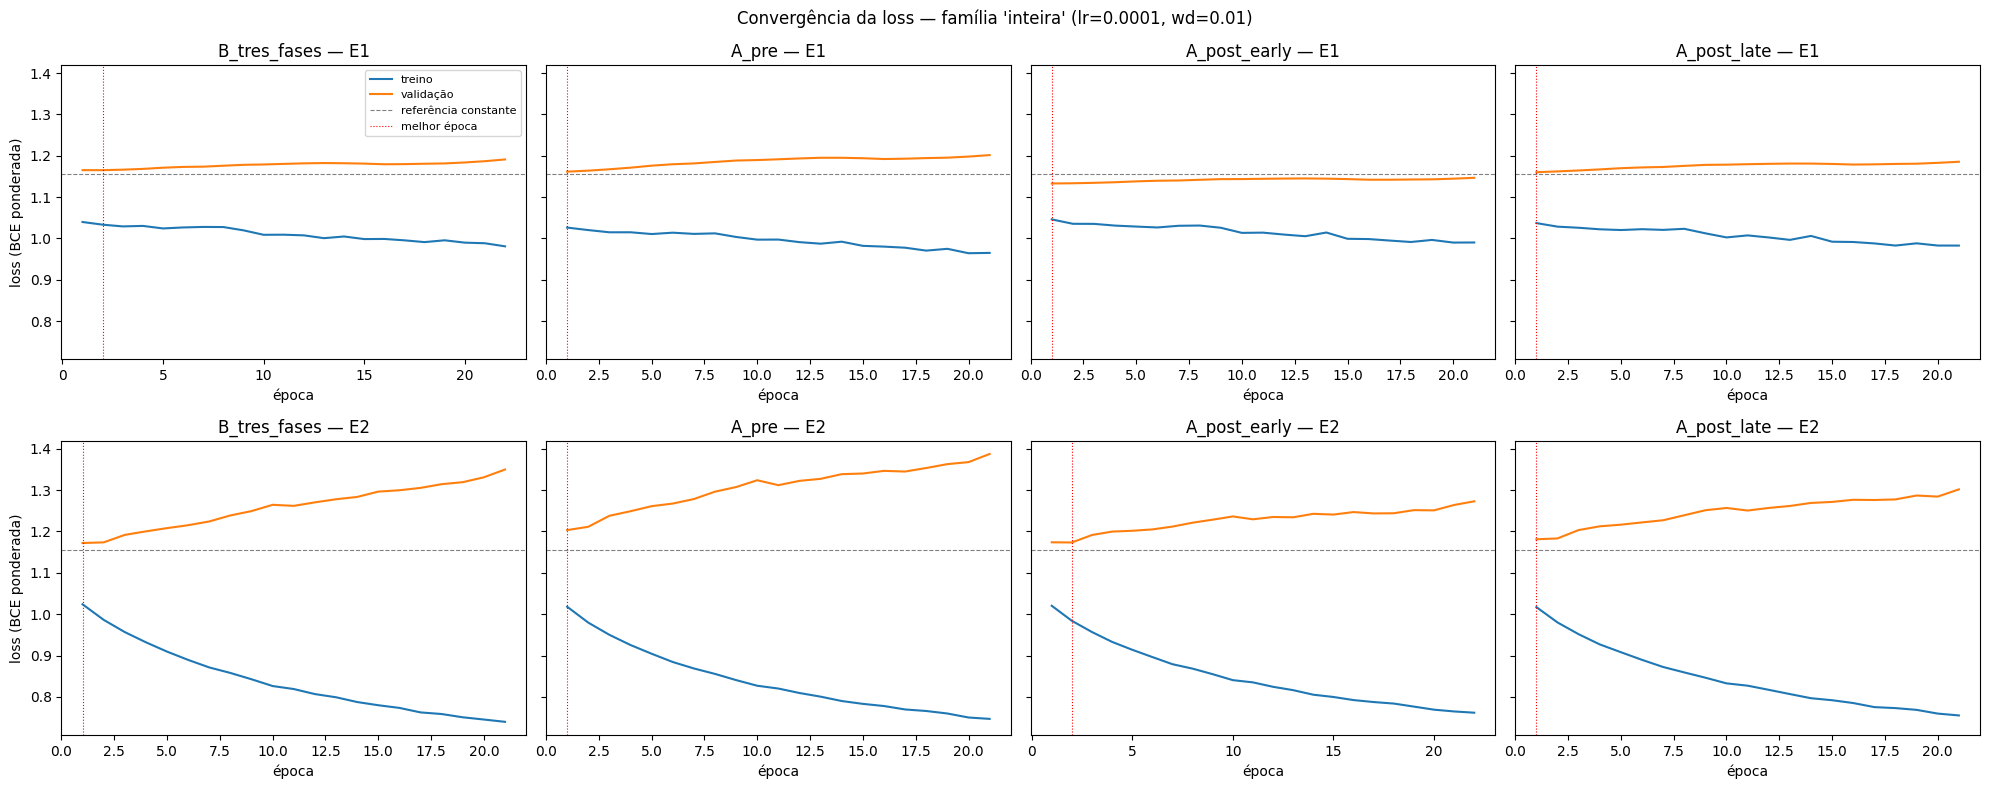

final_recorte_B_tres_fases_E1: já treinado — carregando resultados salvos.
final_recorte_B_tres_fases_E2: já treinado — carregando resultados salvos.
final_recorte_A_pre_E1: já treinado — carregando resultados salvos.
final_recorte_A_pre_E2: já treinado — carregando resultados salvos.
final_recorte_A_post_early_E1: já treinado — carregando resultados salvos.
final_recorte_A_post_early_E2: já treinado — carregando resultados salvos.
final_recorte_A_post_late_E1: já treinado — carregando resultados salvos.
final_recorte_A_post_late_E2: já treinado — carregando resultados salvos.


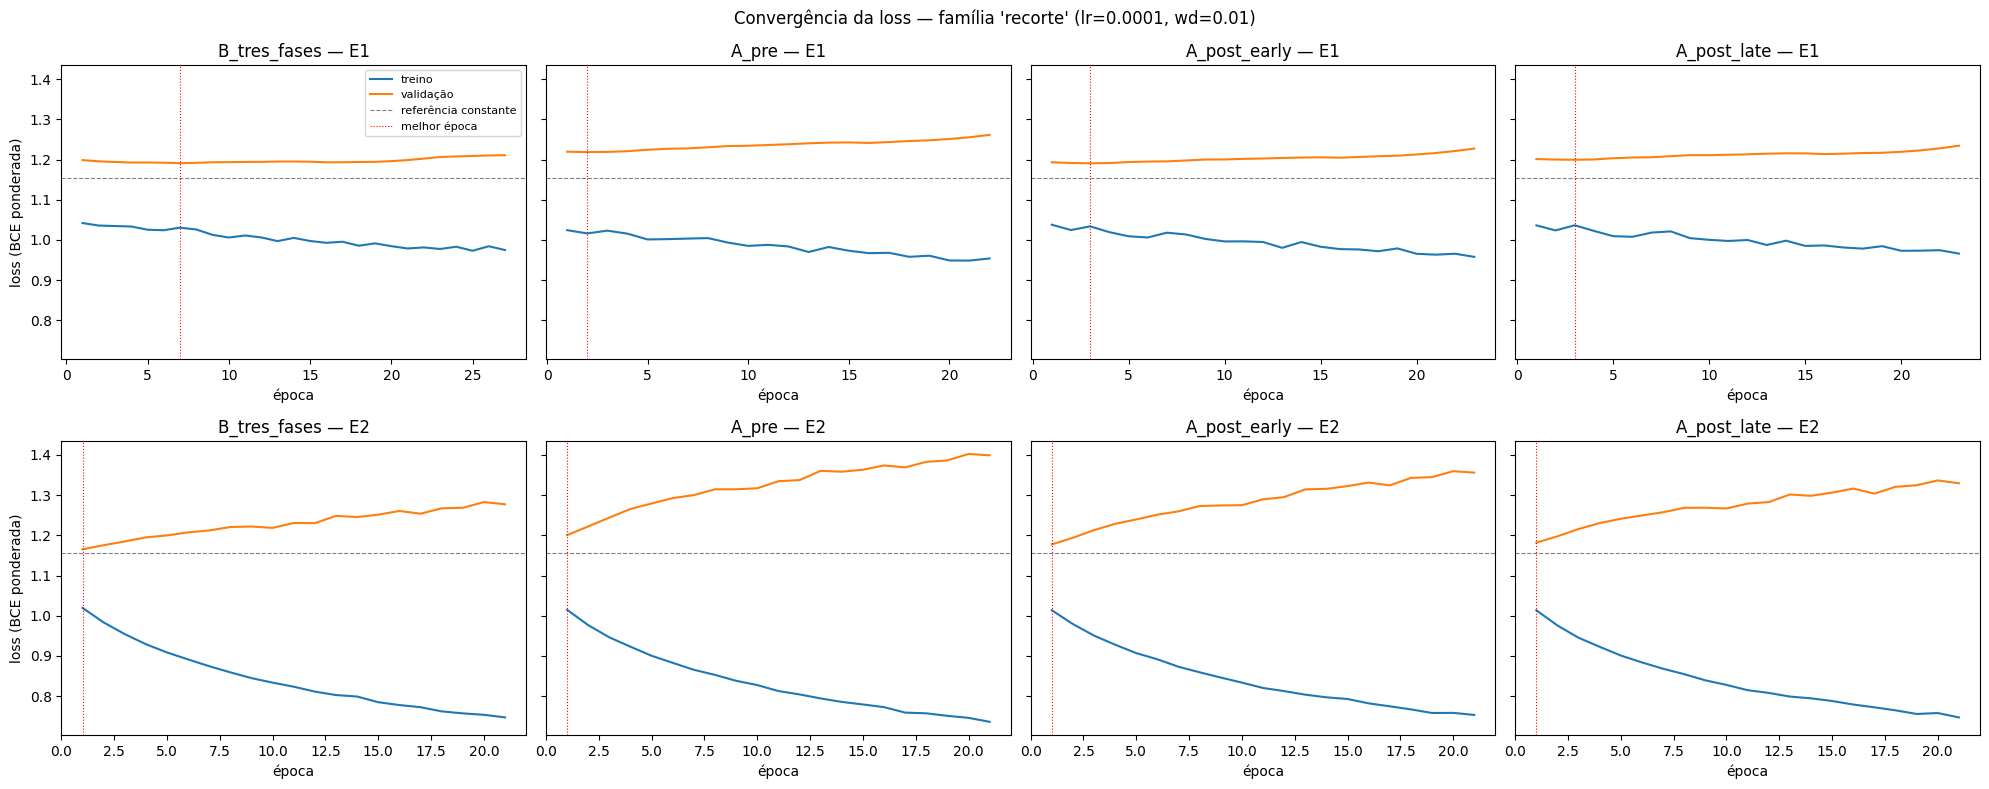

,família,configuração,estratégia,melhor época,épocas,tempo (s),loss val,AUC treino,AUC val,acurácia val,precisão val,sensibilidade val,especificidade val,F1 val
0,inteira,B_tres_fases,1,2,22,0.18,1.165,0.527,0.463,0.485,0.312,0.455,0.500,0.370
1,inteira,B_tres_fases,2,1,21,3.69,1.172,0.822,0.492,0.606,0.417,0.455,0.682,0.435
2,inteira,A_pre,1,1,21,0.20,1.161,0.618,0.455,0.424,0.278,0.455,0.409,0.345
3,inteira,A_pre,2,1,21,3.79,1.203,0.754,0.397,0.667,0.500,0.273,0.864,0.353
4,inteira,A_post_early,1,1,21,0.19,1.133,0.515,0.599,0.455,0.348,0.727,0.318,0.471
5,inteira,A_post_early,2,2,22,4.07,1.173,0.825,0.517,0.606,0.400,0.364,0.727,0.381
6,inteira,A_post_late,1,1,21,0.18,1.160,0.600,0.488,0.424,0.318,0.636,0.318,0.424
7,inteira,A_post_late,2,1,21,3.75,1.181,0.762,0.488,0.606,0.375,0.273,0.773,0.316
8,recorte,B_tres_fases,1,7,27,0.77,1.191,0.701,0.368,0.576,0.333,0.273,0.727,0.300
9,recorte,B_tres_fases,2,1,21,3.29,1.165,0.778,0.467,0.424,0.250,0.364,0.455,0.296


In [11]:
# =====================================================================
# 11. TREINO FINAL DAS CABEÇAS (+ curvas de convergência)
# =====================================================================
import matplotlib.pyplot as plt

HIPER_FINAL = rp.HiperparametrosCabeca(taxa_aprendizado=TAXA_APRENDIZADO, decaimento_pesos=DECAIMENTO_PESOS)
PASTA_MODELOS = os.path.join(PASTA_RESULTADOS, "modelos")
PASTA_FIGURAS = os.path.join(PASTA_RESULTADOS, "figuras")
os.makedirs(PASTA_FIGURAS, exist_ok=True)
REFERENCIA_CONSTANTE = 1.1552   # loss de validação de quem responde sempre 0,5 (calculada na validação oficial)
print("Hiperparâmetros:", HIPER_FINAL)

def carregar_ou_explicar(config, particao, pasta, **opcoes):
    """Carrega as características; se não existirem, explica como gerá-las."""
    try:
        return rp.carregar_caracteristicas(config, particao, pasta=pasta, **opcoes)
    except FileNotFoundError as erro:
        raise FileNotFoundError(
            f"Faltam as características de {config}/{particao} em {pasta}. Este modelo ainda não foi "
            "treinado/avaliado, então elas são necessárias: use GERAR_CARACTERISTICAS = True na célula 1 "
            "e rode as células 9 e 10.") from erro

linhas_resumo = []
for familia, pasta in FAMILIAS.items():
    fig, paineis = plt.subplots(2, 4, figsize=(20, 8), sharey=True)
    for coluna, config in enumerate(rp.CONFIGURACOES_ENTRADA):
        x_tr = reg_tr = x_va = reg_va = None    # só carregadas se algum modelo precisar ser treinado
        for linha_fig, estrategia in enumerate((1, 2)):
            nome = f"final_{familia}_{config}_E{estrategia}"
            destino = os.path.join(PASTA_MODELOS, nome)
            if os.path.exists(os.path.join(destino, "cabeca.pt")):
                print(f"{nome}: já treinado — carregando resultados salvos.")
                with open(os.path.join(destino, "metricas.json")) as arquivo:
                    salvo = json.load(arquivo)
                resumo, metricas = salvo["resumo_treino"], salvo["metricas"]
                historico = pd.read_csv(os.path.join(destino, "historico.csv"))
            else:
                if x_tr is None:
                    x_tr, reg_tr = carregar_ou_explicar(config, "treino", pasta)
                    x_va, reg_va = carregar_ou_explicar(config, "validacao", pasta)
                sel_tr = rp.selecionar_linhas_estrategia(reg_tr, estrategia)
                sel_va = rp.selecionar_linhas_estrategia(reg_va, estrategia)
                cabeca, historico, resumo = rp.treinar_cabeca(
                    x_tr[sel_tr], reg_tr[sel_tr].reset_index(drop=True),
                    x_va[sel_va], reg_va[sel_va].reset_index(drop=True), HIPER_FINAL, dispositivo)
                resumo.update({"familia": familia, "configuracao": config, "estrategia": estrategia})
                previsoes = {
                    "treino": rp.agregar_por_paciente(reg_tr, rp.prever_probabilidades(cabeca, x_tr, dispositivo), estrategia),
                    "validacao": rp.agregar_por_paciente(reg_va, rp.prever_probabilidades(cabeca, x_va, dispositivo), estrategia),
                }
                metricas = {particao: rp.calcular_metricas(tabela) for particao, tabela in previsoes.items()}
                rp.salvar_experimento(nome, cabeca, historico, resumo, previsoes, metricas, pasta=PASTA_RESULTADOS)
                print(f"{nome}: melhor época {resumo['melhor_epoca']}/{resumo['epocas_executadas']} "
                      f"| loss val {resumo['melhor_perda_validacao']:.4f} | AUC val {metricas['validacao']['auc']:.3f} "
                      f"| {resumo['segundos_treino']:.1f} s")

            painel = paineis[linha_fig, coluna]
            painel.plot(historico["epoca"], historico["perda_treino"], label="treino")
            painel.plot(historico["epoca"], historico["perda_validacao"], label="validação")
            painel.axhline(REFERENCIA_CONSTANTE, color="gray", ls="--", lw=0.8, label="referência constante")
            painel.axvline(resumo["melhor_epoca"], color="red", ls=":", lw=0.8, label="melhor época")
            painel.set_title(f"{config} — E{estrategia}")
            painel.set_xlabel("época")
            if coluna == 0:
                painel.set_ylabel("loss (BCE ponderada)")

            mv = metricas["validacao"]
            linhas_resumo.append({
                "família": familia, "configuração": config, "estratégia": estrategia,
                "melhor época": resumo["melhor_epoca"], "épocas": resumo["epocas_executadas"],
                "tempo (s)": resumo["segundos_treino"], "loss val": resumo["melhor_perda_validacao"],
                "AUC treino": metricas["treino"]["auc"], "AUC val": mv["auc"], "acurácia val": mv["acuracia"],
                "precisão val": mv["precisao"], "sensibilidade val": mv["sensibilidade"],
                "especificidade val": mv["especificidade"], "F1 val": mv["f1"],
            })
    paineis[0, 0].legend(fontsize=8)
    fig.suptitle(f"Convergência da loss — família '{familia}' (lr={TAXA_APRENDIZADO:g}, wd={DECAIMENTO_PESOS:g})")
    plt.tight_layout()
    fig.savefig(os.path.join(PASTA_FIGURAS, f"convergencia_final_{familia}.png"), dpi=120)
    plt.show()

resumo_final = pd.DataFrame(linhas_resumo)
resumo_final.to_csv(os.path.join(PASTA_RESULTADOS, "resumo_treinos_finais.csv"), index=False)
display(resumo_final.round(3))

## Avaliação final no teste (uma única vez)

- **O teste só é liberado agora**, depois de todos os modelos salvos. Nada é treinado nem escolhido aqui.
- **A família principal é a imagem inteira**; o recorte é complementar.
- **Rodar de novo não reavalia:** se `metricas_teste.json` já existe, a célula apenas lê o resultado salvo.
- **O intervalo de confiança de 95 % da AUC** (bootstrap de pacientes) é calculado nesta célula. Não é uma função do módulo.

In [12]:
# =====================================================================
# 12. AVALIAÇÃO NO TESTE
# =====================================================================
import numpy as np
from sklearn.metrics import roc_auc_score
gerador = np.random.default_rng(rp.SEMENTE)

def intervalo_auc(previsoes, repeticoes=2000):
    """IC 95 % da AUC por bootstrap: sorteia pacientes com reposição e recalcula a AUC."""
    y, p = previsoes["pCR"].to_numpy(), previsoes["probabilidade"].to_numpy()
    valores = []
    for _ in range(repeticoes):
        i = gerador.integers(0, len(y), len(y))
        if len(set(y[i])) == 2:
            valores.append(roc_auc_score(y[i], p[i]))
    return np.percentile(valores, [2.5, 97.5])

linhas = []
for familia, pasta in FAMILIAS.items():
    for config in rp.CONFIGURACOES_ENTRADA:
        x_te, reg_te = None, None
        for estrategia in (1, 2):
            nome = f"final_{familia}_{config}_E{estrategia}"
            destino = os.path.join(PASTA_MODELOS, nome)
            caminho_metricas = os.path.join(destino, "metricas_teste.json")
            if os.path.exists(caminho_metricas):
                with open(caminho_metricas) as arquivo:
                    metricas = json.load(arquivo)
            else:
                if x_te is None:
                    x_te, reg_te = carregar_ou_explicar(config, "teste", pasta, liberar_teste=True)
                    assert (reg_te["particao"] == "teste").all() and reg_te["original"].all()
                cabeca = rp.criar_cabeca()
                cabeca.load_state_dict(torch.load(os.path.join(destino, "cabeca.pt"), map_location="cpu")["estado_cabeca"])
                cabeca.eval()
                previsoes = rp.agregar_por_paciente(reg_te, rp.prever_probabilidades(cabeca, x_te, dispositivo), estrategia)
                metricas = rp.calcular_metricas(previsoes)
                ic_inf, ic_sup = intervalo_auc(previsoes)
                metricas.update({"auc_ic95_inf": float(ic_inf), "auc_ic95_sup": float(ic_sup)})
                previsoes.to_csv(os.path.join(destino, "previsoes_teste.csv"), index=False)
                with open(caminho_metricas, "w") as arquivo:
                    json.dump(metricas, arquivo, indent=2)
            linhas.append({"família": familia, "configuração": config, "estratégia": f"E{estrategia}",
                           "AUC": metricas["auc"], "AUC IC95%": f"[{metricas['auc_ic95_inf']:.2f}, {metricas['auc_ic95_sup']:.2f}]",
                           "acurácia": metricas["acuracia"], "precisão": metricas["precisao"],
                           "sensibilidade": metricas["sensibilidade"], "especificidade": metricas["especificidade"],
                           "F1": metricas["f1"], "VP": metricas["VP"], "VN": metricas["VN"],
                           "FP": metricas["FP"], "FN": metricas["FN"]})

# Referência: classificador trivial que sempre responde "não pCR"
teste = metadados[metadados["particao"] == "teste"]
negativos, positivos = int((teste["pCR"] == 0).sum()), int((teste["pCR"] == 1).sum())
linhas.append({"família": "referência", "configuração": "sempre não-pCR", "estratégia": "-", "AUC": 0.5, "AUC IC95%": "-",
               "acurácia": negativos / len(teste), "precisão": np.nan, "sensibilidade": 0.0, "especificidade": 1.0,
               "F1": 0.0, "VP": 0, "VN": negativos, "FP": 0, "FN": positivos})
resultados_teste = pd.DataFrame(linhas)
resultados_teste.to_csv(os.path.join(PASTA_RESULTADOS, "resultados_teste_16.csv"), index=False)
print(f"Teste: {len(teste)} pacientes ({positivos} pCR, {negativos} não-pCR)")
display(resultados_teste.round(3))

Teste: 35 pacientes (12 pCR, 23 não-pCR)


,família,configuração,estratégia,AUC,AUC IC95%,acurácia,precisão,sensibilidade,especificidade,F1,VP,VN,FP,FN
0,inteira,B_tres_fases,E1,0.601,"[0.37, 0.83]",0.629,0.467,0.583,0.652,0.519,7,15,8,5
1,inteira,B_tres_fases,E2,0.558,"[0.33, 0.78]",0.543,0.375,0.500,0.565,0.429,6,13,10,6
2,inteira,A_pre,E1,0.525,"[0.29, 0.76]",0.371,0.308,0.667,0.217,0.421,8,5,18,4
3,inteira,A_pre,E2,0.453,"[0.24, 0.67]",0.543,0.300,0.250,0.696,0.273,3,16,7,9
4,inteira,A_post_early,E1,0.540,"[0.30, 0.77]",0.486,0.364,0.667,0.391,0.471,8,9,14,4
5,inteira,A_post_early,E2,0.598,"[0.39, 0.80]",0.600,0.417,0.417,0.696,0.417,5,16,7,7
6,inteira,A_post_late,E1,0.580,"[0.36, 0.79]",0.457,0.348,0.667,0.348,0.457,8,8,15,4
7,inteira,A_post_late,E2,0.572,"[0.35, 0.78]",0.543,0.333,0.333,0.652,0.333,4,15,8,8
8,recorte,B_tres_fases,E1,0.641,"[0.42, 0.84]",0.714,0.583,0.583,0.783,0.583,7,18,5,5
9,recorte,B_tres_fases,E2,0.728,"[0.52, 0.91]",0.629,0.474,0.750,0.565,0.581,9,13,10,3


## Grad-CAM

- **Modelos:** B_tres_fases E1 (corte de maior área tumoral), nas famílias disponíveis, sobre os pacientes da **validação**. É só visualização, sem nenhuma escolha de modelo.
- **Funções do módulo:**
  - `montar_modelo_completo`: junta a ResNet50 ImageNet com a cabeça salva;
  - `gerar_gradcam`: gera o mapa;
  - `sobrepor_gradcam`: desenha o mapa sobre a imagem.
- **Verificação:** o modelo completo deve reproduzir as probabilidades salvas no treino.
- **Concentração no tumor** = fração do mapa dentro do tumor ÷ fração da imagem ocupada pelo tumor. Valor 1 equivale ao acaso. É calculada nesta célula.

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:1072: UserWarning: Attempting to run cuBLAS, but there was no current CUDA context! Attempting to set the primary context... (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/cuda/CublasHandlePool.cpp:410.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


Maior diferença de probabilidade (modelo completo x salvo): 1.84e-07 -> OK


,pacientes,tumor_na_imagem_mediana,calor_no_tumor_mediana,concentracao_mediana,concentracao_maior_1
família,,,,,
inteira,33,0.018,0.019,0.953,16/33
recorte,33,0.077,0.028,0.490,7/33


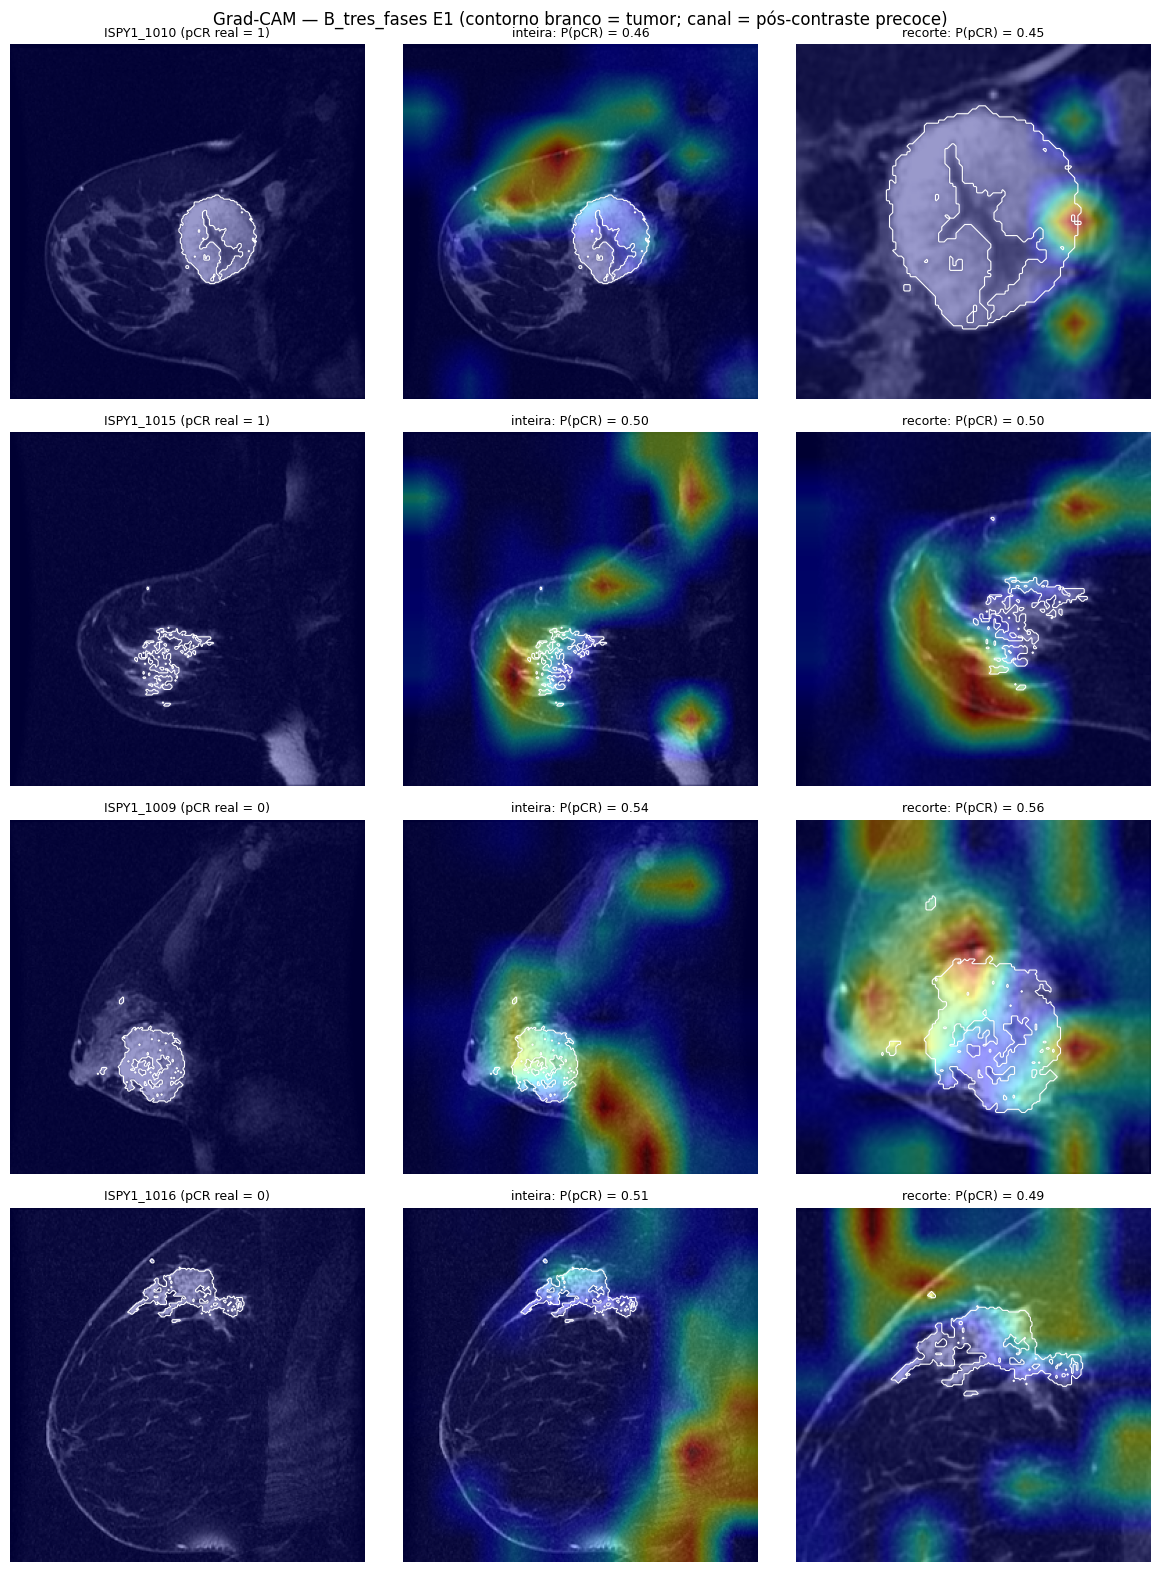

In [13]:
# =====================================================================
# 13. GRAD-CAM (validação)
# =====================================================================
NOMES_GRADCAM = {familia: f"final_{familia}_B_tres_fases_E1" for familia in FAMILIAS}
modelos_cam = {f: rp.montar_modelo_completo(os.path.join(PASTA_MODELOS, n, "cabeca.pt"), dispositivo) for f, n in NOMES_GRADCAM.items()}
prob_salvas = {f: pd.read_csv(os.path.join(PASTA_MODELOS, n, "previsoes_validacao.csv")).set_index("pid")["probabilidade"]
               for f, n in NOMES_GRADCAM.items()}

def entrada_maior_area(paciente, familia):
    """Corte de maior área tumoral (3 fases) e máscara do corte; no recorte, ambos recortados e ampliados."""
    z = rp.selecionar_corte_maior_area(paciente["mascara"])
    corte, mascara = paciente["normalizados"][:, z], paciente["mascara"][z].astype(np.float32)
    if familia == "recorte":
        caixa = rp.caixa_tumoral(paciente["mascara"].any(axis=rp.EIXO_Z))
        corte = rp.recortar_regiao(corte, caixa)
        mascara = rp.recortar_regiao(mascara[np.newaxis], caixa)[0]
    return corte, mascara > 0.5

validacao = metadados[metadados["particao"] == "validacao"]
escolhidos = list(validacao[validacao["pCR"] == 1]["pid"][:2]) + list(validacao[validacao["pCR"] == 0]["pid"][:2])
linhas, exemplos = [], {}
for _, linha in validacao.iterrows():
    paciente = rp.carregar_paciente_normalizado(caminhos, linha, indices[linha["pid"]])
    for familia, modelo_cam in modelos_cam.items():
        imagem, mascara = entrada_maior_area(paciente, familia)
        mapa, probabilidade = rp.gerar_gradcam(modelo_cam, imagem, dispositivo=dispositivo)
        fracao_calor = mapa[mascara].sum() / mapa.sum() if mapa.sum() > 0 else np.nan
        linhas.append({"pid": linha["pid"], "pCR": linha["pCR"], "família": familia,
                       "prob_modelo_completo": probabilidade, "prob_salva_no_treino": prob_salvas[familia][linha["pid"]],
                       "fração_tumor_na_imagem": mascara.mean(), "fração_calor_no_tumor": fracao_calor,
                       "concentração_no_tumor": fracao_calor / mascara.mean()})
        if linha["pid"] in escolhidos:
            exemplos[(linha["pid"], familia)] = (imagem, mapa, mascara, probabilidade)
tabela_gradcam = pd.DataFrame(linhas)
tabela_gradcam.to_csv(os.path.join(PASTA_RESULTADOS, "gradcam_validacao.csv"), index=False)

diferenca = (tabela_gradcam["prob_modelo_completo"] - tabela_gradcam["prob_salva_no_treino"]).abs().max()
print(f"Maior diferença de probabilidade (modelo completo x salvo): {diferenca:.2e} -> {'OK' if diferenca < 1e-3 else 'VERIFICAR'}")
display(tabela_gradcam.groupby("família").agg(
    pacientes=("pid", "size"),
    tumor_na_imagem_mediana=("fração_tumor_na_imagem", "median"),
    calor_no_tumor_mediana=("fração_calor_no_tumor", "median"),
    concentracao_mediana=("concentração_no_tumor", "median"),
    concentracao_maior_1=("concentração_no_tumor", lambda s: f"{(s > 1).sum()}/{len(s)}")).round(3))

familias_cam = list(modelos_cam)
fig, paineis = plt.subplots(len(escolhidos), 1 + len(familias_cam), figsize=(4 * (1 + len(familias_cam)), 4 * len(escolhidos)))
for i, pid in enumerate(escolhidos):
    imagem, _, mascara, _ = exemplos[(pid, "inteira")]
    rotulo = int(validacao.set_index("pid").loc[pid, "pCR"])
    rp.sobrepor_gradcam(paineis[i, 0], imagem[1], np.zeros_like(imagem[1]), mascara, f"{pid} (pCR real = {rotulo})")
    for j, familia in enumerate(familias_cam, start=1):
        imagem, mapa, mascara, probabilidade = exemplos[(pid, familia)]
        rp.sobrepor_gradcam(paineis[i, j], imagem[1], mapa, mascara, f"{familia}: P(pCR) = {probabilidade:.2f}")
fig.suptitle("Grad-CAM — B_tres_fases E1 (contorno branco = tumor; canal = pós-contraste precoce)")
plt.tight_layout()
fig.savefig(os.path.join(PASTA_FIGURAS, "gradcam_validacao.png"), dpi=120)
plt.show()

In [14]:
# =====================================================================
# 14. MODELO COMPLETO PARA A APRESENTAÇÃO (funciona sem internet)
# =====================================================================
# O que foi treinado são só as cabeças (cabeca.pt). O modelo completo = pesos ImageNet + cabeça.
# Aqui salvamos (a) o modelo completo escolhido e (b) uma cópia dos pesos ImageNet,
# para a apresentação não depender de baixar nada.
from torchvision.models import ResNet50_Weights
PASTA_PESOS = os.path.join(PASTA_RESULTADOS, "pesos")
os.makedirs(PASTA_PESOS, exist_ok=True)

modelo_final = rp.montar_modelo_completo(os.path.join(PASTA_MODELOS, MODELO_APRESENTACAO, "cabeca.pt"), torch.device("cpu"))
caminho_completo = os.path.join(PASTA_PESOS, f"resnet50_completa_{MODELO_APRESENTACAO}.pt")
torch.save(modelo_final.state_dict(), caminho_completo)

arquivo_imagenet = os.path.basename(ResNet50_Weights.IMAGENET1K_V2.url)
shutil.copy(os.path.join(torch.hub.get_dir(), "checkpoints", arquivo_imagenet), os.path.join(PASTA_PESOS, arquivo_imagenet))

# Teste: recarregar SEM pesos da internet e comparar a saída
recarregado = rp.criar_resnet50(pesos_imagenet=False)
recarregado.load_state_dict(torch.load(caminho_completo, map_location="cpu"))
recarregado.eval()
entrada = torch.rand(1, 3, 256, 256)
with torch.no_grad():
    iguais = torch.allclose(torch.sigmoid(modelo_final(entrada)), torch.sigmoid(recarregado(entrada)))
print("Arquivos em pesos/:", os.listdir(PASTA_PESOS), "| recarregado igual ao original:", iguais)

Arquivos em pesos/: ['resnet50_completa_final_inteira_B_tres_fases_E2.pt', 'resnet50-11ad3fa6.pth'] | recarregado igual ao original: True


In [15]:
# =====================================================================
# 15. CONFERÊNCIA: todos os arquivos esperados foram gerados?
# =====================================================================
esperados = [os.path.join(PASTA_RESULTADOS, "auditoria_dataset.csv"),
             os.path.join(PASTA_RESULTADOS, "resumo_treinos_finais.csv"),
             os.path.join(PASTA_RESULTADOS, "resultados_teste_16.csv"),
             os.path.join(PASTA_RESULTADOS, "gradcam_validacao.csv"),
             os.path.join(PASTA_FIGURAS, "gradcam_validacao.png"),
             os.path.join(PASTA_PESOS, f"resnet50_completa_{MODELO_APRESENTACAO}.pt"),
             os.path.join(PASTA_PESOS, arquivo_imagenet)]
opcionais = []   # características: só necessárias para treinar/avaliar modelos novos
for familia, pasta in FAMILIAS.items():
    esperados.append(os.path.join(PASTA_FIGURAS, f"convergencia_final_{familia}.png"))
    opcionais.append(os.path.join(pasta, f"tempos_extracao_{familia}.json"))
    for config in rp.CONFIGURACOES_ENTRADA:
        for particao in rp.PARTICOES:
            opcionais.append(os.path.join(pasta, "caracteristicas", f"{config}_{particao}.npy"))
        for estrategia in (1, 2):
            destino = os.path.join(PASTA_MODELOS, f"final_{familia}_{config}_E{estrategia}")
            for arquivo in ("cabeca.pt", "historico.csv", "metricas.json", "previsoes_treino.csv",
                            "previsoes_validacao.csv", "previsoes_teste.csv", "metricas_teste.json"):
                esperados.append(os.path.join(destino, arquivo))
    for particao in rp.PARTICOES:
        opcionais.append(os.path.join(pasta, "caracteristicas", f"registros_{particao}.csv"))

faltando = [caminho for caminho in esperados if not os.path.exists(caminho)]
print(f"Arquivos obrigatórios: {len(esperados)} | presentes: {len(esperados) - len(faltando)} | faltando: {len(faltando)}")
for caminho in faltando:
    print("  FALTA:", caminho)
if not faltando:
    print("Tudo o que é obrigatório foi gerado.")
opcionais_presentes = sum(os.path.exists(caminho) for caminho in opcionais)
print(f"\nCaracterísticas e tempos de extração (opcionais): {opcionais_presentes}/{len(opcionais)} presentes "
      "— só são necessários para treinar ou avaliar modelos novos.")

Arquivos obrigatórios: 121 | presentes: 121 | faltando: 0
Tudo o que é obrigatório foi gerado.

Características e tempos de extração (opcionais): 0/32 presentes — só são necessários para treinar ou avaliar modelos novos.


In [ ]:
# =====================================================================
# 16. (Opcional) ZIP dos resultados leves para download
# =====================================================================
# Inclui modelos (cabeças, históricos, previsões, métricas), figuras e tabelas.
# NÃO inclui as características .npy (~1 GB) nem a pasta pesos/ (~200 MB).
import zipfile
caminho_zip = "/content/resultados_resnet50_leves.zip"
with zipfile.ZipFile(caminho_zip, "w", zipfile.ZIP_DEFLATED) as zipado:
    for atual, _, arquivos in os.walk(PASTA_RESULTADOS):
        if "caracteristicas" in atual.split(os.sep) or "pesos" in atual.split(os.sep):
            continue
        for arquivo in arquivos:
            completo = os.path.join(atual, arquivo)
            zipado.write(completo, os.path.relpath(completo, PASTA_RESULTADOS))
print(f"{caminho_zip}: {os.path.getsize(caminho_zip) / 1e6:.1f} MB")
try:
    from google.colab import files
    files.download(caminho_zip)
except Exception as erro:
    print("Download automático indisponível; baixe pelo painel de arquivos.", erro)

/content/resultados_resnet50_leves.zip: 3.2 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>